In [1]:
########################################################
###################### Importierte Packete #############
########################################################

##### Visualisieren
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import rc                                                   # To use a LaTeX font

##### Calculations and mathematical functions
import numpy as np

##### Data Management
import pandas as pd

##### Scientific functions
import scipy
from scipy import stats
import scipy.constants as sc
from scipy import ndimage
import scipy.signal

from mpl_toolkits import mplot3d                                            # Um 3D Plots zu machen

import os

##### Saving/packing of data
import pickle

In [2]:
# importing the own functions from the scientific_utils package
from scientific_utils.battery.io import Read_Maccor_Txt_Files
from scientific_utils.battery.io import Split_Dataframe_At_Jumps
from scientific_utils.battery.io import Sort_Maccor_Steps_Into_CP_And_OCV


In [3]:
#########################################################
##################### Start of the code ##################
#########################################################

########## Path of the folder with the measurement files ##########
path = '../data/Batt15/raw/cycling' #The input data is in the folder given by path
print('-------------------')
print('The following Path is selected:', path)
print('-------------------')

-------------------
The following Path is selected: ../data/Batt15/raw/cycling
-------------------


In [4]:
########## Handling of the raw data ##########
#############################################

########## List all files in a directory using scandir() ##########

########## Walking a directory tree and printing the names of the directories and files ########## (only for an overview)
#print('-------------------')
#print('The Following folder and File Structure in the given path is found')
#for foldername, subfolders, filenames in os.walk(path):
#    print(f'Found directory: {foldername}')
#    for file_name in filenames:
#        print(file_name)
#print('-------------------')


########## All files and Directories given as a Dataframe ##########
dataframe_of_allfiles = pd.DataFrame(list(os.walk(path)))  # First column: directory/path ; second column: directories in the given directory/path ; third column: files in the given directory/path
                                              # os.walk('path') returns triples (dirpath, dirnames, files) -> list(os.walk('.')) puts these triples in a list


########## Sort the found files by name ##########
FilterbyName1 = '20200903_Batt15_Cyc2p_086.txt'


print('-------------------')
print('Only Files with the following Name are considered:', FilterbyName1)
print('-------------------')

list_of_filenames = dataframe_of_allfiles[2][0]

########## Sorting the battery files ##########
list_of_BatteryMeasurements = sorted([k for k in list_of_filenames if FilterbyName1 in k])

########## Filter by the wanted file format ##########
Format = 'txt'
print('-------------------')
print('Only Files in the Lists with the following Format are considered:', Format)
print('-------------------')

for i in range(len(list_of_BatteryMeasurements)):
    list_of_BatteryMeasurements = [i for i in list_of_BatteryMeasurements if i.endswith(Format)]
print(len(list_of_BatteryMeasurements))

-------------------
Only Files with the following Name are considered: 20200903_Batt15_Cyc2p_086.txt
-------------------
-------------------
Only Files in the Lists with the following Format are considered: txt
-------------------
1


[            Rec#  Cyc#  Step  TestTime (seconds)  StepTime (seconds)  \
0            1.0   0.0   1.0                0.00                0.00   
1            2.0   0.0   1.0                2.50                2.50   
2            3.0   0.0   1.0                5.00                5.00   
3            4.0   0.0   1.0                7.50                7.50   
4            5.0   0.0   1.0               10.00               10.00   
...          ...   ...   ...                 ...                 ...   
537867  537868.0   1.0   9.0          1344062.00             1592.54   
537868  537869.0   1.0   9.0          1344064.50             1595.04   
537869  537870.0   1.0   9.0          1344067.00             1597.54   
537870  537871.0   1.0   9.0          1344069.28             1599.82   
537871  537872.0   1.0  10.0          1344069.28             1599.82   

        Capacity (mAh)  Current (mA)  Voltage (V)  ACR  Unnamed: 9  
0             0.000000        0.0000       3.0650  NaN         Na

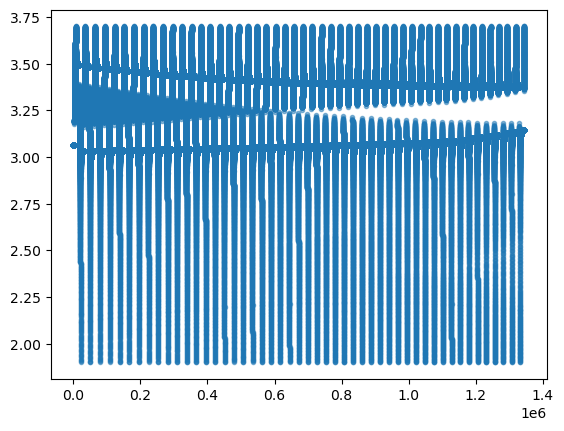

In [5]:
########## Read the files into dataframes ##########
cycling_data_complete = Read_Maccor_Txt_Files(path, list_of_BatteryMeasurements)
print(cycling_data_complete)

plt.plot(cycling_data_complete[0]['TestTime (seconds)'], cycling_data_complete[0]['Voltage (V)'], linestyle='None', alpha=0.5, marker='.', linewidth=1.5)


In [6]:
########## Split the steps into separate dataframes (the step time starts again at zero for every step) #########
list_of_steps = Split_Dataframe_At_Jumps(cycling_data_complete[0], 'StepTime (seconds)', -3)

########## Sort the steps into CP charge, CP discharge, OCV after charge and OCV after discharge ##########
list_of_dataframes_CP_charge_cycling, list_of_dataframes_CP_discharge_cycling, list_of_dataframes_OCV_after_CP_step_charge_cycling, list_of_dataframes_OCV_after_CP_step_discharge_cycling = Sort_Maccor_Steps_Into_CP_And_OCV(list_of_steps, 3.25)

del list_of_dataframes_OCV_after_CP_step_discharge_cycling[0]   # deleting of the first "OCV after discharge" because it is the OCV before the measurements even started

print(len(list_of_dataframes_OCV_after_CP_step_charge_cycling))
print(len(list_of_dataframes_OCV_after_CP_step_discharge_cycling))


99
99
50
49
49
49


In [7]:
########## Save the lists as .pkl file ########
    
########## save the CP steps
##### CP charge steps
with open('../data/Batt15/processed/list_of_dataframes_CP_charge_cycling.pkl', 'wb') as f:
    pickle.dump(list_of_dataframes_CP_charge_cycling, f)   

##### CP discharge steps
with open('../data/Batt15/processed/list_of_dataframes_CP_discharge_cycling.pkl', 'wb') as f:
    pickle.dump(list_of_dataframes_CP_discharge_cycling, f)

    
########## save the OCV steps after the CP step
##### OCVs after a Charging step in the C Rate Test
with open('../data/Batt15/processed/list_of_dataframes_OCV_after_CP_step_charge_cycling.pkl', 'wb') as f:
    pickle.dump(list_of_dataframes_OCV_after_CP_step_charge_cycling, f)

##### OCVs after a Discharging step in the C Rate Test
with open('../data/Batt15/processed/list_of_dataframes_OCV_after_CP_step_discharge_cycling.pkl', 'wb') as f:
    pickle.dump(list_of_dataframes_OCV_after_CP_step_discharge_cycling, f)    